In [23]:
#importar las librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.datasets import fetch_california_housing
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

In [24]:
#cargar el dataset
casas = fetch_california_housing()
X = pd.DataFrame(casas.data, columns = casas.feature_names).drop(columns=["Latitude","AveRooms"])

In [25]:
#test de correlacion
matriz_correlacion = X.corr()

In [29]:
#filtramos las caracteristicas con alta correlacion, > 0.8+
caracteristicas_alta_correlacion = [(col1, col2, matriz_correlacion.loc[col1,col2])
                                   for col1 in matriz_correlacion.columns
                                   for col2 in matriz_correlacion.columns
                                   if col1 != col2 and abs(matriz_correlacion.loc[col1,col2])>0.8]

In [31]:
#Convertir a un dataframe para poder tener una mejor visualizacion
multicolinealidad_df = pd.DataFrame(caracteristicas_alta_correlacion, columns = ["Caracteristica 1","Caracteristica 2","Correlacion"])
print("?\nCaracteristicas altamente correlacionadas:\n", multicolinealidad_df)

?
Caracteristicas altamente correlacionadas:
 Empty DataFrame
Columns: [Caracteristica 1, Caracteristica 2, Correlacion]
Index: []


In [33]:
#VIF, Factor de Inflacion de Varianza por cada caracteristica.
vif_df = pd.DataFrame()
vif_df["Caracteristica"]  = X.columns 
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

In [35]:
print("\nFactor de Inflacion de Varianza (VIF) para cada caracteristica:\n",vif_df)


Factor de Inflacion de Varianza (VIF) para cada caracteristica:
   Caracteristica        VIF
0         MedInc   5.265036
1       HouseAge   7.016556
2      AveBedrms   6.466600
3     Population   2.859849
4       AveOccup   1.094730
5      Longitude  24.292403


In [223]:
y = casas.target

In [225]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [227]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [229]:
from sklearn.linear_model import LinearRegression

In [231]:
model = LinearRegression()
model.fit(X_train_scaler, y_train)

LinearRegression()

In [233]:
y_prediccion = model.predict(X_test_scaler)

In [235]:
from sklearn.metrics import r2_score, mean_squared_error

In [237]:
r2 = r2_score(y_test,y_prediccion)
print(f"R: {r2:.4f}")

R: 0.4960


In [239]:
mse = mean_squared_error(y_test,y_prediccion)
print(f"Error Cuadratico Medio: {mse:.4f}")

Error Cuadratico Medio: 0.6604


In [241]:
rmse = mse**0.5
print(f"Raiz Error Cuadratico Medio: {rmse:.4f}")

Raiz Error Cuadratico Medio: 0.8127


In [249]:
print("Intercepto:", model.intercept_)
coeficientes_df = pd.DataFrame({"Caracteristica": X.columns, "Coeficiente": model.coef_})
print("\nCoeficientes de las caracteristicas:\n", coeficientes_df)

Intercepto: 2.071946937378876

Coeficientes de las caracteristicas:
   Caracteristica  Coeficiente
0         MedInc     0.829385
1       HouseAge     0.234111
2      AveBedrms     0.024433
3     Population     0.042191
4       AveOccup    -0.050487
5      Longitude    -0.020033


Text(0.5, 1.0, 'Importancia de la caracteristica (Coeficiente de la Regresion Lineal)')

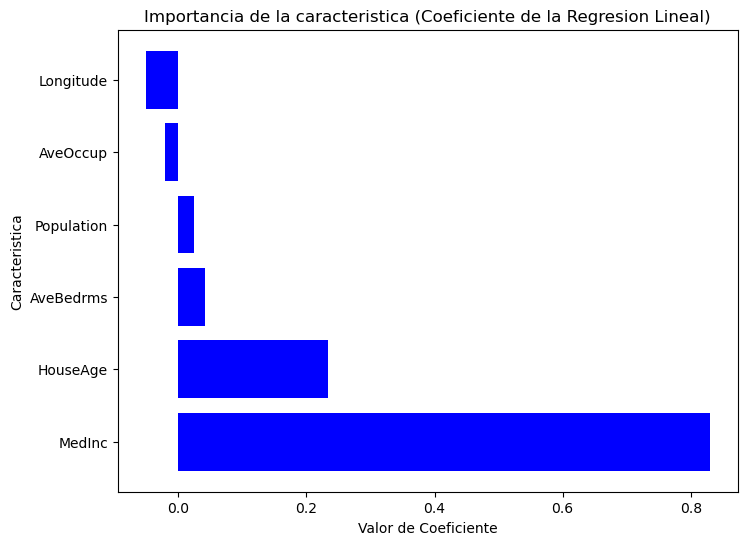

In [252]:
# Ordenar por coeficientes
coeficientes_ordenado_df = coeficientes_df.sort_values(by="Coeficiente", ascending=False)

# Create plot
plt.figure(figsize=(8,6))
plt.barh(coeficientes_df["Caracteristica"], coeficientes_ordenado_df["Coeficiente"],color="blue")
plt.xlabel("Valor de Coeficiente")
plt.ylabel("Caracteristica")
plt.title("Importancia de la caracteristica (Coeficiente de la Regresion Lineal)")